In [1]:
from main_marriages_distances import *

**Mallows Euclidean**

In [2]:
import pandas as pd
import ast
from mapel.marriages.objects.Marriages import Marriages

df = pd.read_csv("euclidean_mallows_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)


In [3]:
instances_euclidean_mallows = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_euclidean_mallows.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [7]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_euclidean_mallows = compute_distance_matrix(instances_euclidean_mallows)

# Print or visualize
print(distance_matrix_euclidean_mallows)


[[0.         6.33478054 6.38509549 ... 4.50746295 4.42875704 4.51755834]
 [6.33478054 0.         6.16927873 ... 5.6863384  5.31141329 5.74388564]
 [6.38509549 6.16927873 0.         ... 4.68021842 4.49913572 4.56362429]
 ...
 [4.50746295 5.6863384  4.68021842 ... 0.         2.50577112 2.86472803]
 [4.42875704 5.31141329 4.49913572 ... 2.50577112 0.         2.79900776]
 [4.51755834 5.74388564 4.56362429 ... 2.86472803 2.79900776 0.        ]]


**Mallows**

In [8]:
df = pd.read_csv("mallows_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [9]:
instances_mallows = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_mallows.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [10]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_mallows = compute_distance_matrix(instances_mallows)

# Print or visualize
print(distance_matrix_mallows)


[[ 0.         15.08310313 13.69306394 ... 10.25323797  9.93587775
  10.30760237]
 [15.08310313  0.         15.55634919 ... 11.44241622 11.19024873
  11.23743743]
 [13.69306394 15.55634919  0.         ... 10.23697004 10.33545677
  10.14954843]
 ...
 [10.25323797 11.44241622 10.23697004 ...  0.          2.61225743
   2.95672491]
 [ 9.93587775 11.19024873 10.33545677 ...  2.61225743  0.
   2.43778132]
 [10.30760237 11.23743743 10.14954843 ...  2.95672491  2.43778132
   0.        ]]


**Mallows MD**

In [11]:
df = pd.read_csv("mallows_MD_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [12]:
instances_mallows_MD = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_mallows_MD.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [13]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_mallows_MD = compute_distance_matrix(instances_mallows_MD)

# Print or visualize
print(distance_matrix_mallows_MD)


[[0.         0.         0.         ... 8.52649466 8.41843216 8.35227846]
 [0.         0.         0.         ... 8.52649466 8.41843216 8.35227846]
 [0.         0.         0.         ... 8.52649466 8.41843216 8.35227846]
 ...
 [8.52649466 8.52649466 8.52649466 ... 0.         2.53245599 2.58618123]
 [8.41843216 8.41843216 8.41843216 ... 2.53245599 0.         2.70277635]
 [8.35227846 8.35227846 8.35227846 ... 2.58618123 2.70277635 0.        ]]


**Mallows MA**

In [14]:
df = pd.read_csv("mallows_MA_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [15]:
instances_mallows_MA = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_mallows_MA.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [16]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_mallows_MA = compute_distance_matrix(instances_mallows_MA)

# Print or visualize
print(distance_matrix_mallows_MA)


[[0.         0.         0.         ... 1.66349699 1.78869909 1.86815417]
 [0.         0.         0.         ... 1.66349699 1.78869909 1.86815417]
 [0.         0.         0.         ... 1.66349699 1.78869909 1.86815417]
 ...
 [1.66349699 1.66349699 1.66349699 ... 0.         2.53880987 2.48808271]
 [1.78869909 1.78869909 1.78869909 ... 2.53880987 0.         2.65193849]
 [1.86815417 1.86815417 1.86815417 ... 2.48808271 2.65193849 0.        ]]


**Reverse Euclidean**

In [17]:
df = pd.read_csv("reverse_euclidean_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [18]:
instances_reverse_euclidean = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_reverse_euclidean.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [19]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_reverse_euclidean = compute_distance_matrix(instances_reverse_euclidean)

# Print or visualize
print(distance_matrix_reverse_euclidean)


[[0.         5.55432764 6.25104436 ... 5.89109497 6.19910388 4.87168691]
 [5.55432764 0.         5.42099827 ... 4.32833045 5.88109022 5.38181093]
 [6.25104436 5.42099827 0.         ... 4.94171585 7.3353785  6.18582609]
 ...
 [5.89109497 4.32833045 4.94171585 ... 0.         6.65703471 5.98298513]
 [6.19910388 5.88109022 7.3353785  ... 6.65703471 0.         5.0365332 ]
 [4.87168691 5.38181093 6.18582609 ... 5.98298513 5.0365332  0.        ]]


**Expectations Euclidean**

In [20]:
df = pd.read_csv("expectations_euclidean_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [21]:
instances_expectations_euclidean = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_expectations_euclidean.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [22]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_expectations_euclidean = compute_distance_matrix(instances_expectations_euclidean)

# Print or visualize
print(distance_matrix_expectations_euclidean)


[[0.         5.14560222 5.72145086 ... 8.06556466 8.40819706 8.07595884]
 [5.14560222 0.         5.57085671 ... 7.51424573 8.71336776 7.39710904]
 [5.72145086 5.57085671 0.         ... 8.37572551 9.32067594 8.89203764]
 ...
 [8.06556466 7.51424573 8.37572551 ... 0.         8.91908067 8.84031171]
 [8.40819706 8.71336776 9.32067594 ... 8.91908067 0.         8.99308376]
 [8.07595884 7.39710904 8.89203764 ... 8.84031171 8.99308376 0.        ]]


**Fame Euclidean**

In [23]:
df = pd.read_csv("fame_euclidean_accomplice.csv")
df.columns = df.columns.str.strip()  # Clean whitespace from headers
df["mpref"] = df["mpref"].apply(ast.literal_eval)
df["wpref"] = df["wpref"].apply(ast.literal_eval)

In [24]:
instances_fame_euclidean = []

for idx, row in df.iterrows():
    try:
        mpref = row["mpref"]
        wpref = row["wpref"]

        # Convert to 0-indexed integer lists
        mpref = [list(map(lambda x: int(x) - 1, list(p))) for p in mpref]
        wpref = [list(map(lambda x: int(x) - 1, list(p))) for p in wpref]

        n_men = len(mpref)
        n_women = len(wpref)

        if n_men != n_women:
            print(f"❌ Row {idx}: unequal men ({n_men}) and women ({n_women}) count")
            continue

        # Sanity check: each list should be of length n_women (for men) and n_men (for women)
        if any(len(p) != n_women for p in mpref) or any(len(p) != n_men for p in wpref):
            print(f"❌ Row {idx}: mismatched preference list lengths")
            continue

        # Merge preferences: first men, then women
        votes = mpref + wpref
        num_agents = len(votes)  # should be 2 * n

        instance_id = f"instance_{idx}"
        """instance = Marriages(
            experiment_id="manipulability_map",
            instance_id=instance_id,
            votes=votes,
            num_agents=num_agents,
            is_imported=False
        )"""
        instance = Marriages(
    experiment_id="manipulability_map",
    instance_id=f"instance_{idx}",
    num_agents=num_agents,
    is_imported=False
)
        instance.votes = votes  # ← assign manually here
        instances_fame_euclidean.append(instance)
    except Exception as e:
        print(f"❌ Error in row {idx}: {e}")


In [25]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

def get_flat_pairwise_vector(instance: Marriages) -> np.ndarray:
    matrix = instance.votes_to_pairwise_matrix()
    return matrix.flatten()

def compute_distance_matrix(instances, metric='euclidean'):
    vectors = [get_flat_pairwise_vector(inst) for inst in instances]
    return squareform(pdist(vectors, metric=metric))

# Create some Marriages instances
#instances = []
#for i, alpha in enumerate([0.5, 1.0, 2.0]):
 #   inst = Marriages(experiment_id='exp', instance_id=f'inst{i}', culture_id='mallows', num_agents=10, is_imported=False)
  #  inst.prepare_instance(params={'alpha': alpha})
   # instances.append(inst)
#print(instances[0].votes)
# Compute the distance matrix
distance_matrix_fame_euclidean = compute_distance_matrix(instances_fame_euclidean)

# Print or visualize
print(distance_matrix_fame_euclidean)


[[ 0.          4.5867563   6.14568503 ...  8.10685581  8.07138292
  10.00247192]
 [ 4.5867563   0.          6.39696108 ...  7.46045128  7.75378044
   8.69226987]
 [ 6.14568503  6.39696108  0.         ...  7.971233    9.3756185
   9.5289617 ]
 ...
 [ 8.10685581  7.46045128  7.971233   ...  0.         10.8580999
  10.32776732]
 [ 8.07138292  7.75378044  9.3756185  ... 10.8580999   0.
  11.00610941]
 [10.00247192  8.69226987  9.5289617  ... 10.32776732 11.00610941
   0.        ]]


In [26]:
import numpy as np

def combine_distance_matrices(distance_matrices, fill_value=None):
    """
    Combine multiple distance matrices into one big distance matrix.
    
    Parameters:
        distance_matrices (list of np.ndarray): list of square distance matrices.
        fill_value (float or None): value to fill for cross-dataset distances.
                                    If None, will use max distance in all matrices.
    
    Returns:
        combined_matrix (np.ndarray): combined distance matrix.
    """
    sizes = [dm.shape[0] for dm in distance_matrices]
    total_size = sum(sizes)
    
    # Determine fill value for off-diagonal blocks
    if fill_value is None:
        max_distance = max(dm.max() for dm in distance_matrices)
        fill_value = max_distance * 1.1  # a bit larger than max
    
    # Initialize big matrix with fill_value
    combined_matrix = np.full((total_size, total_size), fill_value, dtype=float)
    
    # Place each distance matrix on the diagonal
    start = 0
    for dm in distance_matrices:
        size = dm.shape[0]
        combined_matrix[start:start+size, start:start+size] = dm
        start += size
    
    # Distance to self = 0 (diagonal)
    np.fill_diagonal(combined_matrix, 0)
    
    return combined_matrix


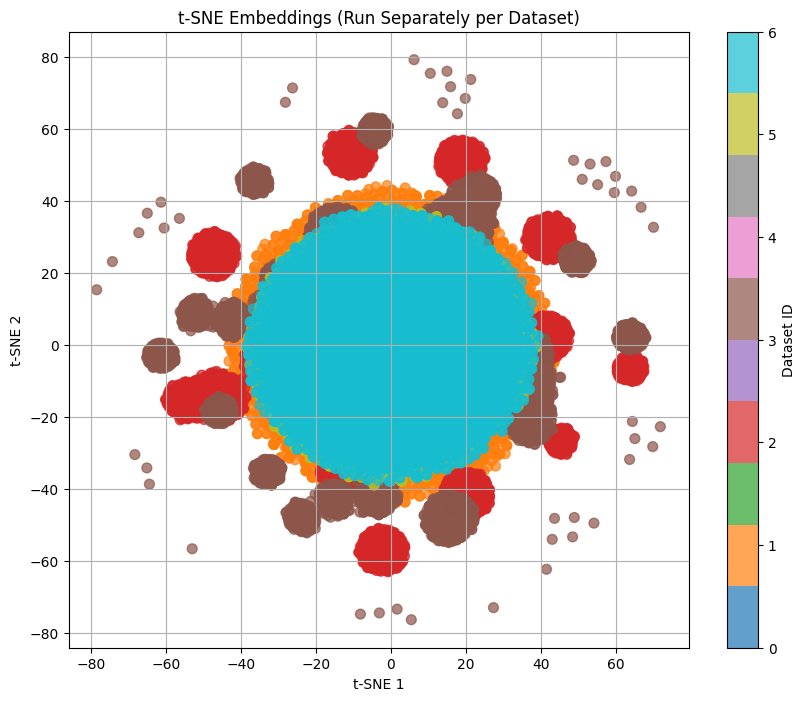

In [27]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

def run_tsne_on_distance_matrix(dist_matrix, label_id, perplexity=30):
    tsne = TSNE(n_components=2, metric='precomputed', init='random', perplexity=perplexity, random_state=42)
    embedding = tsne.fit_transform(dist_matrix)
    labels = [label_id] * len(dist_matrix)
    return embedding, labels

# Process one dataset at a time
results = []

datasets = [
    (distance_matrix_euclidean_mallows, 0),
    (distance_matrix_mallows, 1),
    (distance_matrix_mallows_MD, 2),
    (distance_matrix_mallows_MA, 3),
    (distance_matrix_reverse_euclidean, 4),
    (distance_matrix_expectations_euclidean, 5),
    (distance_matrix_fame_euclidean, 6),
]

for dist, label_id in datasets:
    emb, lbls = run_tsne_on_distance_matrix(dist, label_id)
    results.append((emb, lbls))

# Combine all embeddings and labels
all_embeddings = np.vstack([r[0] for r in results])
all_labels = sum([r[1] for r in results], [])

# Plot
plt.figure(figsize=(10, 8))
scatter = plt.scatter(all_embeddings[:, 0], all_embeddings[:, 1], c=all_labels, cmap='tab10', alpha=0.7, s=50)
plt.colorbar(scatter, ticks=range(len(datasets)), label='Dataset ID')
plt.title("t-SNE Embeddings (Run Separately per Dataset)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.show()


In [30]:
# Say you have three distance matrices:

combined_dist = combine_distance_matrices([distance_matrix, distance_matrix_mallows, distance_matrix_mallows_MD, distance_matrix_mallows_MA, distance_matrix_reverse_euclidean, distance_matrix_expectations_euclidean, distance_matrix_fame_euclidean])

# Now run t-SNE on combined_dist:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, metric='precomputed', init='random', random_state=42)
embeddings = tsne.fit_transform(combined_dist)

# Plot embeddings and color by dataset
import matplotlib.pyplot as plt

labels = ([0] * distance_matrix.shape[0]) + ([1] * distance_matrix_mallows.shape[0])
plt.scatter(embeddings[:, 0], embeddings[:, 1], c=labels, cmap='tab10')
plt.colorbar(ticks=[0, 1, 2], label='Dataset')
plt.show()


: 

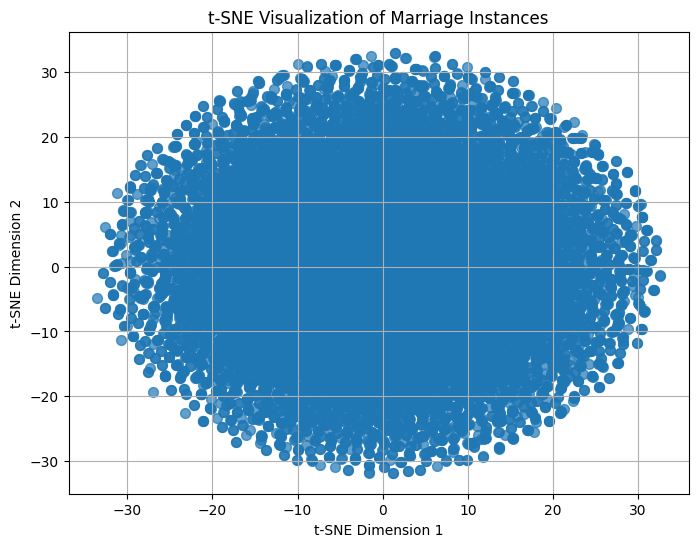

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# distance_matrix: your precomputed NxN distance matrix

tsne = TSNE(n_components=2, metric='precomputed', init='random', random_state=42)
embeddings = tsne.fit_transform(distance_matrix)

plt.figure(figsize=(8, 6))
plt.scatter(embeddings[:, 0], embeddings[:, 1], s=50, alpha=0.7)
plt.title('t-SNE Visualization of Marriage Instances')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.grid(True)
plt.show()
